# Analysis 7: How concentrated are the trending lists?

**Business question.** Is the trending list open to many creators, or do a few channels take most of the space? For a new creator or a brand, a concentrated list is harder to break into.

**Metric.** Each appearance of a video on a day's list is one list slot. A channel's share is its number of slots. Concentration is measured with the Lorenz curve (cumulative share of slots against cumulative share of channels) and the Gini coefficient (0 when every channel has the same number of slots, close to 1 when one channel has almost all of them), with 95% bootstrap confidence intervals.

**Important scope note.** Only channels that trended at least once are counted. The millions of channels that never trended are not in the data, so these numbers describe concentration among successful channels and understate concentration across YouTube as a whole.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from streampulse.analysis import bootstrap_ci, gini, lorenz_curve
from streampulse.charts import COUNTRIES, COUNTRY_COLORS, COUNTRY_NAMES, apply_chart_style
from streampulse.database import connect

apply_chart_style()
with connect() as connection:
    channel_slots_by_year = connection.execute("""
        SELECT country, channel_id, any_value(channel_title) AS channel_title, category,
               year(trending_date) AS trending_year, count(*) AS list_slots
        FROM trending
        GROUP BY country, channel_id, category, trending_year
    """).df()

channel_slots = (
    channel_slots_by_year.groupby(["country", "channel_id"])
    .agg(channel_title=("channel_title", "first"), list_slots=("list_slots", "sum"))
    .reset_index()
)

## 1. Lorenz curves and Gini coefficients

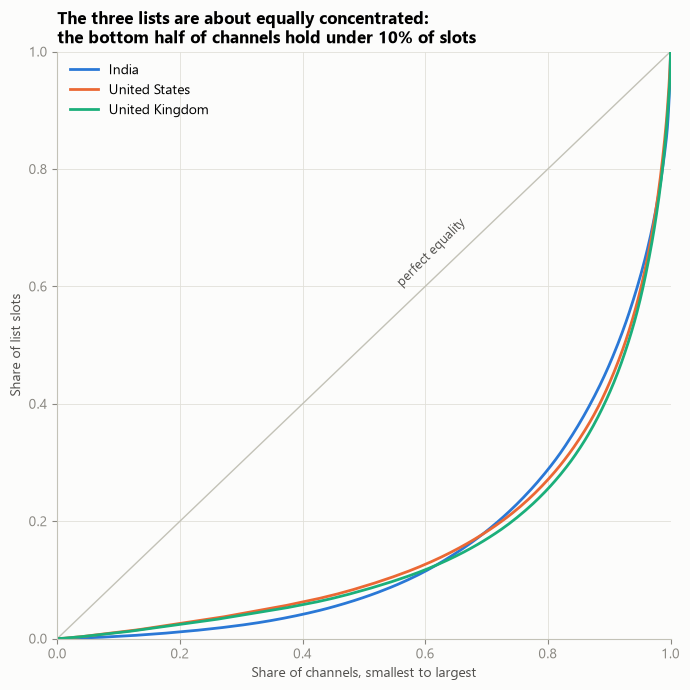

,channels,gini,gini_ci_low,gini_ci_high,pct_slots_top_1pct_channels,pct_slots_top_10_channels,channels_holding_half_of_slots,median_slots_per_channel,pct_channels_holding_half
country,,,,,,,,,
IN,4521,0.683,0.666,0.699,17.602,7.947,392,20.0,8.671
US,8302,0.674,0.664,0.684,15.444,3.471,627,10.0,7.552
GB,7571,0.689,0.676,0.703,16.876,5.259,533,10.0,7.040


In [2]:
summary_rows = []
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1)
ax.text(0.55, 0.6, "perfect equality", rotation=45, fontsize=9, color="#52514e")
for country in COUNTRIES:
    slots = channel_slots.loc[channel_slots["country"] == country, "list_slots"].to_numpy()
    share_of_channels, share_of_slots = lorenz_curve(slots)
    ax.plot(share_of_channels, share_of_slots, color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
    largest_first = np.sort(slots)[::-1]
    cumulative_share = np.cumsum(largest_first) / largest_first.sum()
    ci_low, ci_high = bootstrap_ci(slots, gini)
    summary_rows.append({
        "country": country,
        "channels": len(slots),
        "gini": gini(slots),
        "gini_ci_low": ci_low,
        "gini_ci_high": ci_high,
        "pct_slots_top_1pct_channels": 100 * largest_first[: max(1, len(slots) // 100)].sum() / slots.sum(),
        "pct_slots_top_10_channels": 100 * largest_first[:10].sum() / slots.sum(),
        "channels_holding_half_of_slots": int(np.searchsorted(cumulative_share, 0.5)) + 1,
        "median_slots_per_channel": np.median(slots),
    })
ax.set_xlabel("Share of channels, smallest to largest")
ax.set_ylabel("Share of list slots")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("The three lists are about equally concentrated:\n"
             "the bottom half of channels hold under 10% of slots")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

concentration = pd.DataFrame(summary_rows).set_index("country")
concentration["pct_channels_holding_half"] = 100 * concentration["channels_holding_half_of_slots"] / concentration["channels"]
concentration.round(3)

In [3]:
bottom_half_share = {}
for country in COUNTRIES:
    slots = np.sort(channel_slots.loc[channel_slots["country"] == country, "list_slots"].to_numpy())
    bottom_half_share[country] = 100 * slots[: len(slots) // 2].sum() / slots.sum()
pd.Series(bottom_half_share, name="pct_slots_held_by_bottom_half_of_channels").round(1)

IN    7.0
US    8.9
GB    8.3
Name: pct_slots_held_by_bottom_half_of_channels, dtype: float64

## 2. Who holds the most space

In [4]:
top_channels = (
    channel_slots.assign(pct_of_country_slots=lambda rows: 100 * rows["list_slots"]
                         / rows.groupby("country")["list_slots"].transform("sum"))
    .sort_values("list_slots", ascending=False)
    .groupby("country").head(8)
)
pd.concat(
    {COUNTRY_NAMES[country]: top_channels[top_channels["country"] == country]
     .reset_index(drop=True)[["channel_title", "list_slots", "pct_of_country_slots"]]
     for country in COUNTRIES},
    axis=1,
).round(2)

India                                  \
        channel_title list_slots pct_of_country_slots   
0    Vijay Television       3363                 1.36   
1  Sourav Joshi Vlogs       2841                 1.15   
2            Sony SAB       2614                 1.05   
3              Sun TV       2083                 0.84   
4         HAR PAL GEO       1640                 0.66   
5             Asianet       1569                 0.63   
6         ARY Digital       1530                 0.62   
7           Colors TV       1503                 0.61   

                    United States                                  \
                    channel_title list_slots pct_of_country_slots   
0                             NFL       1792                 0.68   
1                             NBA       1450                 0.55   
2                         MrBeast       1114                 0.42   
3                      NBC Sports        795                 0.30   
4  Champions League on CBS Sports        716                 0.27   
5                    Dude Perfect        687                 0.26   
6                  Big Hit Labels        678                 0.26   
7                            ESPN        673                 0.25   

        United Kingdom                                  
         channel_title list_slots pct_of_country_slots  
0  Sky Sports Football       2861                 1.08  
1     The United Stand       2683                 1.01  
2             BT Sport       1931                 0.73  
3          MoreSidemen       1311                 0.49  
4            FORMULA 1       1292                 0.49  
5                  WWE       1029                 0.39  
6              Sidemen        950                 0.36  
7              MrBeast        640                 0.24

## 3. Over time

Gini by calendar year. A Gini computed over a shorter period is lower because channels have less time to build up slots, so only the three full years (2021 to 2023) are compared; 2020 (from 12 August) and 2024 (to 15 April) are partial and shown only in the table.

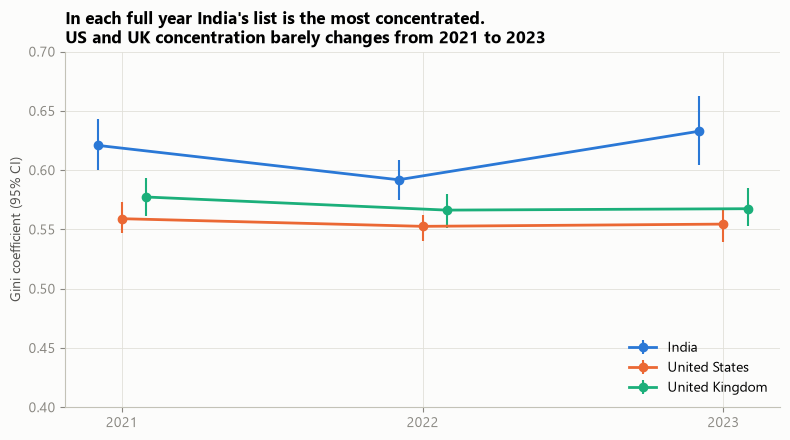

country,IN,US,GB
trending_year,,,
2020,0.555,0.483,0.504
2021,0.621,0.559,0.577
2022,0.592,0.553,0.566
2023,0.633,0.554,0.567
2024,0.570,0.411,0.440


In [5]:
yearly_slots = channel_slots_by_year.groupby(["country", "trending_year", "channel_id"])["list_slots"].sum()
yearly_gini = yearly_slots.groupby(["country", "trending_year"]).agg(gini).unstack("country")[COUNTRIES]
yearly_ci = {
    (country, year): bootstrap_ci(yearly_slots.loc[(country, year)].to_numpy(), gini, n_resamples=300)
    for country in COUNTRIES for year in [2021, 2022, 2023]
}

fig, ax = plt.subplots(figsize=(8, 4.5))
for offset, country in zip([-0.08, 0, 0.08], COUNTRIES):
    years = np.array([2021, 2022, 2023])
    values = yearly_gini.loc[years, country].to_numpy()
    errors = np.array([[values[i] - yearly_ci[(country, year)][0], yearly_ci[(country, year)][1] - values[i]]
                       for i, year in enumerate(years)]).T
    ax.errorbar(years + offset, values, yerr=errors, fmt="o-", markersize=6, color=COUNTRY_COLORS[country],
                elinewidth=1.5, capsize=0, label=COUNTRY_NAMES[country])
ax.set_xticks([2021, 2022, 2023])
ax.set_ylim(0.4, 0.7)
ax.set_ylabel("Gini coefficient (95% CI)")
ax.set_title("In each full year India's list is the most concentrated.\n"
             "US and UK concentration barely changes from 2021 to 2023")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

yearly_gini.round(3)

## 4. By category

Gini within each category, for categories with at least 100 channels in a country.

In [6]:
category_slots = channel_slots_by_year.groupby(["country", "category", "channel_id"])["list_slots"].sum()
category_concentration = (
    category_slots.groupby(["country", "category"]).agg(channels="size", gini=gini).reset_index()
    .query("channels >= 100")
)
category_concentration.pivot(index="category", columns="country", values="gini")[COUNTRIES].sort_values("US", ascending=False).round(3)

country,IN,US,GB
category,,,
Sports,0.640,0.739,0.737
Education,0.675,0.717,0.707
Science & Technology,0.726,0.690,0.684
Gaming,0.659,0.684,0.673
Entertainment,0.729,0.672,0.691
Howto & Style,0.624,0.671,0.651
Comedy,0.660,0.660,0.646
Film & Animation,0.643,0.657,0.643
People & Blogs,0.684,0.636,0.659


## Finding

**A small group of channels holds most of the trending space, to a similar degree in all three countries.**

- **Gini is 0.67 to 0.69 in every country** over the whole period: India 0.683 (95% CI 0.666 to 0.699), US 0.674 (0.664 to 0.684), UK 0.689 (0.676 to 0.703). The intervals overlap, so overall the three lists are about equally concentrated.
- **What that means in practice:** 7% to 9% of trending channels (392 in India, 627 in the US, 533 in the UK) hold half of all list slots. The top 1% of channels hold 15% to 18%. The bottom half of channels hold only 7% (India) to 9% (US) of slots.
- **Top channels differ by market.** India's list is led by TV networks (Vijay Television, SAB TV, Sun TV, Colors TV), Pakistani drama channels (HAR PAL GEO, ARY Digital) and one vlogger (Sourav Joshi Vlogs). The US is led by sports leagues and broadcasters (NFL, NBA, NBC Sports, ESPN) and MrBeast; the UK by football and sports media (Sky Sports, The United Stand, BT Sport, Formula 1) and the Sidemen. India's top 10 channels hold 7.9% of slots, against 5.3% (UK) and 3.5% (US).
- **Within a single year India is the most concentrated** (Gini 0.59 to 0.63 in 2021 to 2023, against 0.55 to 0.58 for the US and UK). US and UK concentration barely moves over those three years.
- **By category,** Sports is the most concentrated in the US and UK (Gini 0.74), where leagues and official broadcasters dominate; in India the most concentrated are Entertainment (0.73) and Science & Technology (0.73). News & Politics is among the least concentrated everywhere (0.56 to 0.64).

**Business answer.** Breaking into the trending list means competing with a small set of established channels that take about half the space. In India those are TV networks; in the US and UK, sports organisations and a few large creators.

**Limitations**

- Only channels that trended at least once are counted, so concentration across all of YouTube is much higher.
- Gini depends on the time window: a whole-period Gini is higher than a yearly one, and partial years (2020, 2024) are lower, so only equal windows should be compared.
- Channel names are taken from one appearance; a few channels changed names during the period.